# Постановка задачи

Описание кейса: необходимо спрогнозировать точное количество
минут до завершения доставки с момента размещения заказа на
основе времени приготовления блюд, дистанции, категории пробок,
погоды и характеристик курьера.

Датасет: https://www.kaggle.com/datasets/razanihababdellatif/food-delivery-orders-and-eta-logistics-dataset

# Загрузка и подготовка данных

## Импорт библиотек

In [1]:
from itertools import product
from pathlib import Path
from time import perf_counter

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostRegressor
from IPython.display import display

## Импорт данных

In [ ]:
path = kagglehub.dataset_download(
    "razanihababdellatif/food-delivery-orders-and-eta-logistics-dataset"
)

print("Path to dataset files:", path)

100%|██████████| 2.55M/2.55M [00:00<00:00, 83.9MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/razanihababdellatif/food-delivery-orders-and-eta-logistics-dataset/versions/1


In [3]:
dataset_dir = Path(path)

for file in dataset_dir.rglob("*"):
    if file.is_file():
        print(file.relative_to(dataset_dir))

food_delivery_orders_dataset.csv


In [4]:
df = pd.read_csv(dataset_dir / "food_delivery_orders_dataset.csv")

# EDA

## Обзор датасета

In [5]:
df.head()

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,...,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,...,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             50000 non-null  object 
 1   customer_id                          50000 non-null  object 
 2   restaurant_id                        50000 non-null  object 
 3   driver_id                            50000 non-null  object 
 4   order_timestamp                      50000 non-null  object 
 5   order_date                           50000 non-null  object 
 6   order_hour                           50000 non-null  int64  
 7   day_of_week                          50000 non-null  object 
 8   is_weekend                           50000 non-null  int64  
 9   city                                 50000 non-null  object 
 10  delivery_area                        50000 non-null  object 
 11  customer_age                

## Первичный анализ и очистка

### Первичный анализ данных

1. Все пропуски (столбцы tip_amount, actual_delivery_time_minutes, late_delivery, customer_rating) связаны с отмененными заказами. 868 отменённых заказов можно отбросить по причине того, что там не указано время доставки, а также нужно убрать полностью столбец cancellation_reason: причина становится известна только уже после отмены заказа и бесполезна для предугадывания продолжительности доставки из-за отсутствия на старте



In [7]:
print("Размер:", df.shape)
print("Дубликатов строк:", df.duplicated().sum())

miss = df.isna().sum()
miss = pd.DataFrame({"пропусков": miss, "доля_%": miss / len(df) * 100})
miss[miss["пропусков"] > 0].sort_values("пропусков", ascending=False)

Размер: (50000, 37)
Дубликатов строк: 0


,пропусков,доля_%
cancellation_reason,49132,98.264
tip_amount,868,1.736
actual_delivery_time_minutes,868,1.736
late_delivery,868,1.736
customer_rating,868,1.736


In [8]:
cols = [
    "tip_amount",
    "actual_delivery_time_minutes",
    "late_delivery",
    "customer_rating",
    "cancellation_reason",
]
print("\nПропуски в колонках у отменённых и у остальных заказов:")
df.groupby("order_status")[cols].apply(lambda g: g.isna().sum())


Пропуски в колонках у отменённых и у остальных заказов:


,tip_amount,actual_delivery_time_minutes,late_delivery,customer_rating,cancellation_reason
order_status,,,,,
Cancelled,868,868,868,868,0
Completed,0,0,0,0,49132


### Рабочая копия и очистка данных

In [9]:
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.2f}".format)
sns.set_theme(style="whitegrid")

TARGET = "actual_delivery_time_minutes"

data = df.copy()
data["order_timestamp"] = pd.to_datetime(data["order_timestamp"])
data["order_date"] = pd.to_datetime(data["order_date"])

print("data:", data.shape)
print("Размеры совпадают:", df.shape == data.shape)

data: (50000, 37)
Размеры совпадают: True


In [10]:
print("До очистки:   ", data.shape)

data = data[data["order_status"] == "Completed"].copy()
data = data.drop(columns=["cancellation_reason"])

print("После очистки:", data.shape)
print("Осталось пропусков во всей таблице:", data.isna().sum().sum())

До очистки:    (50000, 37)
После очистки: (49132, 36)
Осталось пропусков во всей таблице: 0


### Логические проверки
- Невозможных значений нет: расстояние, количество блюд, суммы, время, скидки, чаевые в допустимых пределах.
- `order_total` сходится с компонентами (расхождение до 0,01, округление), то есть линейно выражается через `subtotal`, `discount_percent`, `tax_amount`, `service_fee`, `delivery_fee`. При анализе корреляций ждём избыточность между этими колонками. - тут подумать как сократить количество колонок
- `late_delivery` = 1, если `actual - estimated > 5` мин. Значит, эта колонка выводится из таргета и является утечкой.
- 32 заказа (0,07%), где доставка быстрее приготовления на 1–2 мин, при коротких расстояниях (до 2,3 км). Оставлено как шум.
- Час в `order_hour` согласован с `order_timestamp`. Период: 1–30 октября.
- Убираем утечки `customer_rating`, `order_status`(объяснение ниже в действии)
- У `tip_amount` корреляция с таргетом слабая(0,19) и неизвестно является ли это утечкой(когда именно клиент оставляет чаевые до заказа или после?) - убираем



In [11]:
checks = {
    "distance_km <= 0": (data["distance_km"] <= 0).sum(),
    "items_count <= 0": (data["items_count"] <= 0).sum(),
    "subtotal <= 0": (data["subtotal"] <= 0).sum(),
    "prep_time <= 0": (data["restaurant_preparation_time_minutes"] <= 0).sum(),
    "actual_time <= 0": (data[TARGET] <= 0).sum(),
    "estimated_time <= 0": (data["estimated_delivery_time_minutes"] <= 0).sum(),
    "tip < 0": (data["tip_amount"] < 0).sum(),
    "discount вне 0..100": (~data["discount_percent"].between(0, 100)).sum(),
}
pd.Series(checks, name="проблемных строк")

,проблемных строк
distance_km <= 0,0
items_count <= 0,0
subtotal <= 0,0
prep_time <= 0,0
actual_time <= 0,0
estimated_time <= 0,0
tip < 0,0
discount вне 0..100,0


In [12]:
# 1. Доставка не может быть быстрее, чем готовится блюдо (время доставки считается от момента заказа)
fast = data[TARGET] < data["restaurant_preparation_time_minutes"]
print("Доставка быстрее времени приготовления:", fast.sum())

# 2. late_delivery должен совпадать с правилом (actual - estimated) > 5 мин
rule = ((data[TARGET] - data["estimated_delivery_time_minutes"]) > 5).astype(float)
print(
    "late_delivery не совпадает с (actual - estimated) > 5:", (data["late_delivery"] != rule).sum()
)


# 3. Сумма заказа сходится с компонентами?
calc = (
    data["subtotal"] * (1 - data["discount_percent"] / 100)
    + data["tax_amount"]
    + data["service_fee"]
    + data["delivery_fee"]
)
print("order_total - расчётная сумма:")
print((data["order_total"] - calc).describe().round(2))


# 4. Время и час заказа согласованы
print(
    "order_hour не совпадает с часом в order_timestamp:",
    (data["order_timestamp"].dt.hour != data["order_hour"]).sum(),
)
print("Период данных:", data["order_date"].min().date(), "-", data["order_date"].max().date())

Доставка быстрее времени приготовления: 32
late_delivery не совпадает с (actual - estimated) > 5: 0
order_total - расчётная сумма:
count   49132.00
mean       -0.00
std         0.00
min        -0.01
25%        -0.00
50%         0.00
75%         0.00
max         0.01
dtype: float64
order_hour не совпадает с часом в order_timestamp: 0
Период данных: 2025-10-01 - 2025-10-30


In [13]:
# Убираем также утечки (задержка доставки, рейтинг заказа(его ставит пользователь после уже), состояние заказа всегда выполнено)

data = data.drop(columns=["late_delivery", "customer_rating", "order_status"])
print(data.shape)

(49132, 33)


### Спорная колонка `tip_amount` - убираем
Проверяли, не является ли она утечкой (зависит ли от итога доставки).
- Корреляция с таргетом слабая (0,19), сильной связи с временем доставки нет.
- В описании датасета не сказано, когда оставляются чаевые и видит ли их курьер. Нужно решить самостоятельно

In [14]:
print("Корреляция tip_amount и таргета:", round(data["tip_amount"].corr(data[TARGET]), 2))

Корреляция tip_amount и таргета: 0.19


In [15]:
(
    data[["tip_amount", TARGET, "order_total", "items_count", "distance_km"]]
    .corr()[["tip_amount"]]
    .drop("tip_amount")
    .sort_values("tip_amount", ascending=False)
    .style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1)
    .format("{:.2f}")
)

,tip_amount
order_total,0.44
items_count,0.35
actual_delivery_time_minutes,0.19
distance_km,0.01


### Открытые вопросы
1. `tip_amount`: когда оставляют чаевые (при оформлении заказа или после доставки)? От этого зависит, утечка это или нет.
2. `estimated_delivery_time_minutes`: в описании датасета не указано, как он считается. Можно попробовать использовать как baseline решение - в модели не используем

# Анализ отдельных признаков

### Анализ категориальных колонок

- Проверено 8 колонок: опечаток, разного регистра и пропусков нет.
- Редкие категории: `Fine Dining` (2,4%) и `Storm` (2,6%), но по числу заказов (более 1000) достаточно для анализа.
- Заметные перекосы: `Fast Food` 55% заказов, `Clear` 57% по погоде.
- `traffic_level` имеет естественный порядок (Low < Medium < High).
- `delivery_area` здесь 40 значений: 4 города × 10 районов(Районы привязаны к конкретному городу 1 город = 10 районов) В районах распределено примерно одинаковое количество заказов

In [16]:
id_cols = ["order_id", "customer_id", "restaurant_id", "driver_id"]
cat_cols = [
    c for c in data.select_dtypes(exclude=["number", "datetime"]).columns if c not in id_cols
]

data[cat_cols].nunique().sort_values()

,0
customer_type,3
payment_method,3
traffic_level,3
restaurant_type,4
weather,4
city,4
restaurant_primary_category,6
day_of_week,7
delivery_area,40


In [17]:
small_cats = [c for c in cat_cols if c != "delivery_area"]

for c in small_cats:
    vc = data[c].value_counts(dropna=False)
    print(f"--- {c} ---")
    print(pd.DataFrame({"заказов": vc, "доля_%": (vc / len(data) * 100).round(1)}))
    print()

--- day_of_week ---
             заказов  доля_%
day_of_week                 
Thursday        8316   16.90
Wednesday       8050   16.40
Saturday        6595   13.40
Tuesday         6558   13.30
Sunday          6556   13.30
Monday          6540   13.30
Friday          6517   13.30

--- city ---
        заказов  доля_%
city                   
City_A    19527   39.70
City_B    14627   29.80
City_C    10006   20.40
City_D     4972   10.10

--- customer_type ---
               заказов  доля_%
customer_type                 
Regular          24672   50.20
Premium          14452   29.40
New              10008   20.40

--- restaurant_type ---
                 заказов  доля_%
restaurant_type                 
Fast Food          27106   55.20
Casual Dining      12848   26.10
Cafe                7999   16.30
Fine Dining         1179    2.40

--- restaurant_primary_category ---
                             заказов  доля_%
restaurant_primary_category                 
Burger                         15

In [18]:
print("Районов в каждом городе:")
print(data.groupby("city")["delivery_area"].nunique())

area_city = data.groupby("delivery_area")["city"].nunique()
print("\nРайонов, которые встречаются больше чем в одном городе:", (area_city > 1).sum())

vc = data["delivery_area"].value_counts()
print("\nСамые частые районы:")
print(vc.head(5))
print("\nСамые редкие районы:")
print(vc.tail(5))

Районов в каждом городе:
city
City_A    10
City_B    10
City_C    10
City_D    10
Name: delivery_area, dtype: int64

Районов, которые встречаются больше чем в одном городе: 0

Самые частые районы:
delivery_area
City_A_Area_1    2020
City_A_Area_7    1990
City_A_Area_9    1976
City_A_Area_5    1970
City_A_Area_2    1958
Name: count, dtype: int64

Самые редкие районы:
delivery_area
City_D_Area_9    495
City_D_Area_4    487
City_D_Area_2    486
City_D_Area_1    484
City_D_Area_6    475
Name: count, dtype: int64


### Анализ целевой переменной(таргета)
- 49 132 заказа, среднее 35,2 мин, медиана 33 мин, типичный диапазон (25–75%) 25–42 мин, минимум 10, максимум 172.
- Распределение скошено вправо (skew 1,43, kurtosis 3,83): основная масса заказов в 20–50 мин, длинный хвост долгих доставок.
- После log1p распределение близко к симметричному: ML-специалисту стоит рассмотреть прогноз логарифма таргета.
- Выбросов (дольше ~67 мин) много, но они образуют плавный хвост

count   49132.00
mean       35.15
std        14.70
min        10.00
25%        25.00
50%        33.00
75%        42.00
max       172.00
Name: actual_delivery_time_minutes, dtype: float64
skew: 1.43 | kurtosis: 3.83


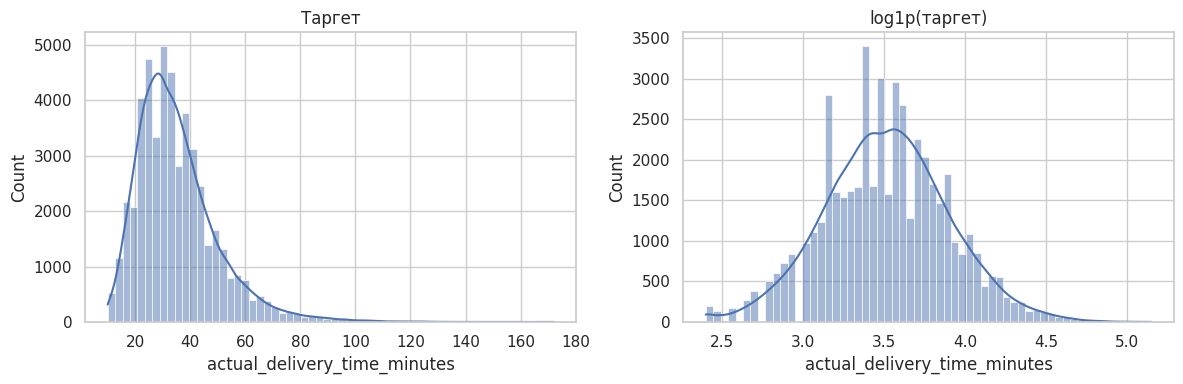

In [19]:
y = data[TARGET]
print(y.describe())
print("skew:", round(y.skew(), 2), "| kurtosis:", round(y.kurt(), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y, bins=60, kde=True, ax=ax[0])
ax[0].set_title("Таргет")
sns.histplot(np.log1p(y), bins=60, kde=True, ax=ax[1])
ax[1].set_title("log1p(таргет)")
plt.tight_layout()
plt.show()

### Анализ выбросов

- Больше всего выбросов в денежных колонках: `tip_amount` (8,0%), `service_fee`, `subtotal`, `order_total`, `tax_amount` (5,2–5,7%). Длинный правый хвост: крупные заказы (до 443 по `order_total`). Эти колонки связаны формулой, выбросы, вероятно, приходятся на одни и те же заказы.
- `distance_km`: 4,4% выбросов (> 10,55 км), максимум ровно 20 км.
- Время: таргет 3,4% (> 67,5 мин, максимум 172), `estimated_delivery_time_minutes` 3,5%, `restaurant_preparation_time_minutes` 2,9%.
- Остальные колонки: выбросов мало (до 0,4%) или нет.
- `distance_km`: ровно 20,00 км у 78 заказов (0,16%), при этом от 19 до 20 км всего 34. Похоже на ограничение сверху (расстояния больше 20 км записаны как 20), в описании датасета об этом не сказано. Значение 20 км вероятно означает «20 и больше», но их мало и не удаляем, можно как фичу использовать(>=20)

In [20]:
num_cols = data.select_dtypes("number").columns.drop(["is_weekend"]).tolist()

rows = []
for c in num_cols:
    q1, q3 = data[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((data[c] < lo) | (data[c] > hi)).sum()
    rows.append((c, n_out, n_out / len(data) * 100, lo, hi, data[c].min(), data[c].max()))

out = pd.DataFrame(
    rows,
    columns=["колонка", "выбросов", "доля_%", "нижняя_граница", "верхняя_граница", "min", "max"],
)
out.sort_values("доля_%", ascending=False).round(2)

,колонка,выбросов,доля_%,нижняя_граница,верхняя_граница,min,max
10,tip_amount,3913,7.96,-3.42,5.70,0.00,53.65
7,service_fee,2810,5.72,-1.39,3.86,0.13,25.21
4,subtotal,2606,5.30,-27.49,80.72,5.10,362.98
9,order_total,2552,5.19,-29.47,95.57,4.87,443.21
6,tax_amount,2540,5.17,-3.76,10.88,0.57,50.82
11,distance_km,2135,4.35,-1.85,10.55,0.80,20.00
15,estimated_delivery_time_minutes,1714,3.49,-0.50,59.50,8.00,128.00
16,actual_delivery_time_minutes,1657,3.37,-0.50,67.50,10.00,172.00
14,restaurant_preparation_time_minutes,1429,2.91,-3.50,32.50,5.00,73.00
3,items_count,967,1.97,-3.50,8.50,1.00,10.00


In [21]:
print("Заказов с расстоянием ровно 20 км:", (data["distance_km"] == 20).sum())
print("Заказов с расстоянием больше 19 км:", (data["distance_km"] > 19).sum())

Заказов с расстоянием ровно 20 км: 78
Заказов с расстоянием больше 19 км: 112


## Связь признаков с таргетом

### Корреляция числовых признаков с нашим таргетом `actual_time` (По Пирсону)
- Сильные: `estimated_delivery_time_minutes` (0,93), `distance_km` (0,77).
- Умеренные: `restaurant_preparation_time_minutes` (0,50), денежные колонки (`order_total`, `subtotal`, `tax_amount`, `service_fee`, 0,42–0,46), `items_count` (0,38), `delivery_fee` (0,34).
- Слабые: `tip_amount` (0,19), `order_hour` (0,06).
- Практически нулевые: `is_weekend`, `restaurant_rating`, `customer_age`, `discount_percent`, `delivery_partner_rating`, `delivery_partner_experience_months`.
- Денежные колонки (`order_total`, `subtotal`, `tax_amount`, `service_fee`) связаны между собой на 0,94–1,00: дублируют друг друга (размер заказа). Размер заказа связан с временем приготовления (0,81–0,87), через него, вероятно, и влияет на таргет.
- Категориальные колонки не разбирались

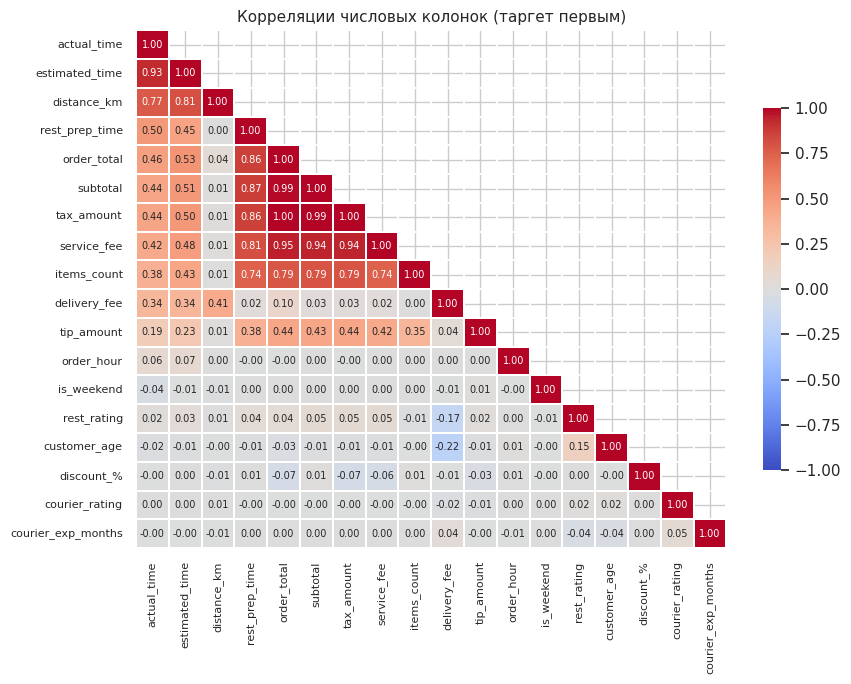

In [22]:
short = {
    "restaurant_preparation_time_minutes": "rest_prep_time",
    "estimated_delivery_time_minutes": "estimated_time",
    "actual_delivery_time_minutes": "actual_time",
    "delivery_partner_experience_months": "courier_exp_months",
    "delivery_partner_rating": "courier_rating",
    "restaurant_rating": "rest_rating",
    "discount_percent": "discount_%",
}

num_cols = data.select_dtypes("number").columns.tolist()
corr = data[num_cols].corr().rename(index=short, columns=short)

# таргет первым, дальше признаки по убыванию силы связи с ним
order = corr["actual_time"].abs().sort_values(ascending=False).index
corr = corr.loc[order, order]
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.3,
    annot_kws={"size": 7},
    cbar_kws={"shrink": 0.7},
)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.title("Корреляции числовых колонок (таргет первым)", fontsize=11)
plt.tight_layout()
plt.show()

### Категориальные признаки.

**Пробки (`traffic_level`).** Среднее время доставки растёт с загруженностью: Low 30,6 мин → Medium 35,0 → High 39,9 (разница около 9 минут).
**Погода (`weather`).** Clear 33,6, Cloudy 35,1, Rain 39,2, Storm 47,1 мин. Clear и Cloudy отличаются слабо, Rain заметно дольше, Storm +13,5 мин к ясной погоде.
- В плохих условиях растёт и разброс (std): Low 11,8 → High 16,6; Clear 13,5 → Storm 21,1, то есть время доставки менее предсказуемо.
- Среднее монотонно растёт по порядку Low < Medium < High и Clear < Cloudy < Rain < Storm: возможно порядковое кодирование.

**Тип ресторана и время приготовления.** Среднее время приготовления: Cafe 11,9 → Fast Food 14,4 → Casual Dining 19,0 → Fine Dining 28,5 мин. Разница между типами в приготовлении (16,6 мин между Cafe и Fine Dining) почти равна разнице во времени доставки (16,4): `restaurant_type` влияет на таргет практически через `restaurant_preparation_time_minutes`. Вместе с временем приготовления тип ресторана мало что добавляет (гипотеза, не проверена на модели).

**Районы (`delivery_area`).** Внутри города средние по районам различаются не более чем на 0,7–1,6 мин, что сопоставимо с погрешностью среднего (около ±0,7 мин для самого мелкого района). Районы малоинформативны сверх `city`, сам `city` влияет слабо (34,1–36,0 мин).

In [23]:
for c in ["traffic_level", "weather"]:
    print(f"--- {c} ---")
    print(
        data.groupby(c)[TARGET].agg(["count", "mean", "median", "std"]).round(1).sort_values("mean")
    )
    print()

--- traffic_level ---
               count  mean  median   std
traffic_level                           
Low            14987 30.60   29.00 11.80
Medium         19197 35.00   33.00 14.00
High           14948 39.90   37.00 16.60

--- weather ---
         count  mean  median   std
weather                           
Clear    27857 33.60   31.00 13.50
Cloudy   12581 35.10   33.00 14.30
Rain      7427 39.20   36.00 16.50
Storm     1267 47.10   42.00 21.10



In [24]:
for c in [
    "city",
    "customer_type",
    "restaurant_type",
    "restaurant_primary_category",
    "payment_method",
    "day_of_week",
]:
    print(f"--- {c} ---")
    print(
        data.groupby(c)[TARGET].agg(["count", "mean", "median", "std"]).round(1).sort_values("mean")
    )
    print()

--- city ---
        count  mean  median   std
city                             
City_C  10006 34.10   31.00 14.50
City_A  19527 35.00   32.00 14.60
City_D   4972 35.50   33.00 14.70
City_B  14627 36.00   33.00 15.00

--- customer_type ---
               count  mean  median   std
customer_type                           
Premium        14452 34.70   32.00 14.60
Regular        24672 35.20   33.00 14.70
New            10008 35.70   33.00 14.70

--- restaurant_type ---
                 count  mean  median   std
restaurant_type                           
Cafe              7999 31.30   29.00 13.60
Fast Food        27106 34.10   32.00 14.10
Casual Dining    12848 38.60   36.00 15.10
Fine Dining       1179 47.70   44.00 17.70

--- restaurant_primary_category ---
                             count  mean  median   std
restaurant_primary_category                           
Burger                       15905 34.00   31.00 14.20
Local                        12498 35.00   32.00 14.60
Dessert        

In [25]:
# 1. Верно ли, что тип ресторана влияет на время доставки через время приготовления?
print(
    data.groupby("restaurant_type")["restaurant_preparation_time_minutes"]
    .agg(["mean", "median"])
    .round(1)
    .sort_values("mean")
)

# 2. Районы: насколько отличается среднее время доставки между районами внутри одного города?
a = data.groupby(["city", "delivery_area"])[TARGET].mean().round(1)
print(a.groupby("city").agg(["min", "max"]))

                 mean  median
restaurant_type              
Cafe            11.90   11.00
Fast Food       14.40   13.00
Casual Dining   19.00   18.00
Fine Dining     28.50   26.00
         min   max
city              
City_A 34.60 35.30
City_B 35.40 37.00
City_C 33.50 34.70
City_D 35.00 36.20


### Зависимость времени доставки от часа заказа


**Час заказа.** Среднее время доставки зависит от часа ступенчато: ночью (0–5) 30–32 мин, днём вне пиков около 34, в часы пик 12–14 и 19–21 около 37 минут. Но при одинаковом уровне пробок время в часы пик и вне их практически не отличается (High 39,9 и 39,8; Medium 35,1 и 35,0; Low 30,8 и 30,6): влияние часа объясняется пробками (в часы пик High-пробок 49% заказов против 14% вне пиков).

Если `traffic_level` используется в модели, час или признак «час пик» почти ничего не добавят. Если пробки на момент прогноза неизвестны, час может служить их заменой.

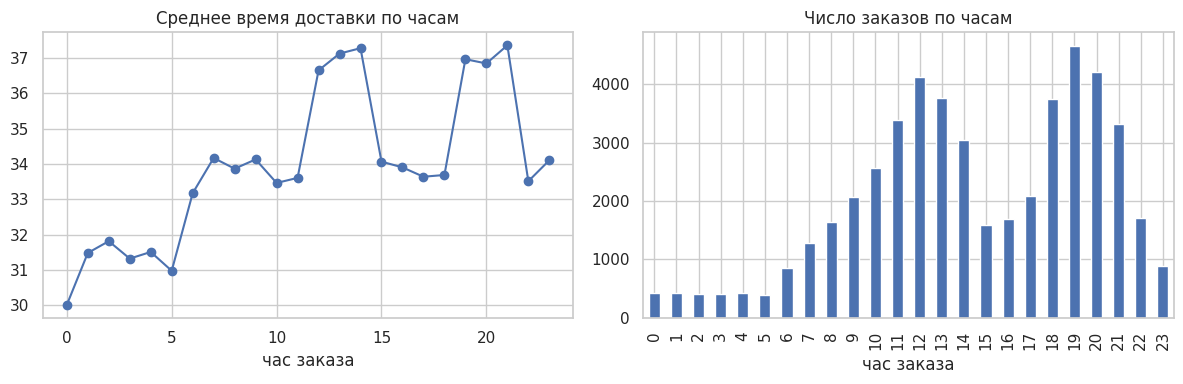

In [26]:
by_hour = data.groupby("order_hour")[TARGET].agg(["count", "mean"])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
by_hour["mean"].plot(marker="o", ax=ax[0], title="Среднее время доставки по часам")
ax[0].set_xlabel("час заказа")
by_hour["count"].plot(kind="bar", ax=ax[1], title="Число заказов по часам")
ax[1].set_xlabel("час заказа")
plt.tight_layout()
plt.show()

In [27]:
rush = data["order_hour"].isin([12, 13, 14, 19, 20, 21]).rename("часы_пик")

print("Доля уровней пробок в часы пик и вне их:")
print(pd.crosstab(rush, data["traffic_level"], normalize="index").round(2))

print("\nСреднее время доставки (часы пик × пробки):")
print(data.groupby([rush, "traffic_level"])[TARGET].mean().unstack().round(1))

Доля уровней пробок в часы пик и вне их:
traffic_level  High  Low  Medium
часы_пик                        
False          0.14 0.49    0.37
True           0.49 0.10    0.41

Среднее время доставки (часы пик × пробки):
traffic_level  High   Low  Medium
часы_пик                         
False         39.80 30.60   35.00
True          39.90 30.80   35.10


### Основные числовые факторы: расстояние и время приготовления

- `distance_km`: время доставки растёт почти линейно, примерно на 4 минуты на каждый километр (до 1 км: 20,1 мин; 3–5 км: 32,1; 7–10 км: 49,4; 15–20 км: 86,8). Дальше 10 км рост немного круче.
- `restaurant_preparation_time_minutes`: каждая дополнительная минута приготовления добавляет примерно минуту к доставке (до 10 мин: 27,4; 20–25 мин: 42,0; 40+ мин: 67,2). Подтверждает, что приготовление входит в общее время.
- Расстояние и время приготовления не связаны друг с другом (корреляция 0,00): их влияния независимы и суммируются.

In [28]:
for col, bins in [
    ("distance_km", [0, 1, 2, 3, 5, 7, 10, 15, 20.1]),
    ("restaurant_preparation_time_minutes", [0, 10, 15, 20, 25, 30, 40, 80]),
]:
    g = data.groupby(pd.cut(data[col], bins), observed=True)[TARGET].agg(["count", "mean"]).round(1)
    print(f"--- {col} ---")
    print(g)
    print()

--- distance_km ---
              count  mean
distance_km              
(0.0, 1.0]      338 20.10
(1.0, 2.0]     4929 22.80
(2.0, 3.0]     9576 26.40
(3.0, 5.0]    17242 32.10
(5.0, 7.0]     9277 39.90
(7.0, 10.0]    5259 49.40
(10.0, 15.0]   2072 64.20
(15.0, 20.1]    439 86.80

--- restaurant_preparation_time_minutes ---
                                     count  mean
restaurant_preparation_time_minutes             
(0, 10]                              12434 27.40
(10, 15]                             15997 32.60
(15, 20]                             10469 37.50
(20, 25]                              5629 42.00
(25, 30]                              2591 47.10
(30, 40]                              1611 54.10
(40, 80]                               401 67.20



### Остальные числовые признаки (курьер, рейтинг, возраст, размер заказа)
- `delivery_partner_experience_months`, `delivery_partner_rating`: среднее время доставки одинаково во всех диапазонах (35,0–35,5 мин). Колонки про курьера не несут сигнала.
- `customer_age`: влияния нет (34,5–35,4 мин).
- `restaurant_rating`: небольшие колебания без закономерности (34,3–36,7 мин), слабое влияние или шум.
- `items_count`: сильная монотонная зависимость, около +2,6 минуты на каждое блюдо (1 блюдо: 30,1 мин; 9–10 блюд: 53,9).

In [29]:
checks = [
    ("delivery_partner_experience_months", [0, 6, 12, 24, 36, 48, 60]),
    ("delivery_partner_rating", [3, 3.5, 4, 4.5, 5.01]),
    ("restaurant_rating", [2.7, 3.5, 4, 4.5, 5.01]),
    ("customer_age", [17, 25, 35, 45, 55]),
    ("items_count", [0, 1, 2, 4, 6, 8, 10]),
]

for col, bins in checks:
    g = data.groupby(pd.cut(data[col], bins), observed=True)[TARGET].agg(["count", "mean"]).round(1)
    print(f"--- {col} ---")
    print(g)
    print()

--- delivery_partner_experience_months ---
                                    count  mean
delivery_partner_experience_months             
(0, 6]                               5828 35.00
(6, 12]                              5101 35.30
(12, 24]                            10266 35.30
(24, 36]                             9735 35.10
(36, 48]                             9593 35.10
(48, 60]                             8609 35.10

--- delivery_partner_rating ---
                         count  mean
delivery_partner_rating             
(3.0, 3.5]                 210 35.40
(3.5, 4.0]                5444 35.50
(4.0, 4.5]               21539 35.00
(4.5, 5.01]              21939 35.20

--- restaurant_rating ---
                   count  mean
restaurant_rating             
(2.7, 3.5]          2812 36.70
(3.5, 4.0]         16697 34.30
(4.0, 4.5]         16394 35.40
(4.5, 5.01]        13229 35.60

--- customer_age ---
              count  mean
customer_age             
(17, 25]      20850 35.40
(25, 

### Взаимодействие признаков
- Расстояние × пробки: разница High и Low растёт с расстоянием (3,0 мин при 0–2 км → 25,8 мин при 10–20 км): пробки удлиняют каждый километр (примерно 2,8 / 3,6 / 4,5 мин на км при Low / Medium / High).
- Расстояние × погода: аналогично, разница Storm и Clear растёт с 5,3 мин (0–2 км) до 33,9 мин (10–20 км).
- Пробки × погода: отношение времени при разной погоде примерно постоянно при любых пробках (Storm/Clear около 1,4, Rain/Clear около 1,15–1,19).
- Время приготовления × пробки: разница High и Low около 9–9,5 мин при любом времени приготовления: пробки влияют только на дорогу, приготовление просто прибавляется.

In [30]:
pv = data.pivot_table(
    index=pd.cut(data["distance_km"], [0, 2, 4, 6, 10, 20.1]),
    columns="traffic_level",
    values=TARGET,
    aggfunc="mean",
    observed=True,
).round(1)[["Low", "Medium", "High"]]
_ = pv

traffic_level,Low,Medium,High
distance_km,,,
"(0.0, 2.0]",21.10,22.60,24.10
"(2.0, 4.0]",25.60,28.30,31.40
"(4.0, 6.0]",31.30,35.60,41.00
"(6.0, 10.0]",39.40,46.30,54.00
"(10.0, 20.1]",55.20,67.70,81.00


In [31]:
w = ["Clear", "Cloudy", "Rain", "Storm"]
t = ["Low", "Medium", "High"]

print("--- Расстояние × погода ---")
print(
    data.pivot_table(
        index=pd.cut(data["distance_km"], [0, 2, 4, 6, 10, 20.1]),
        columns="weather",
        values=TARGET,
        aggfunc="mean",
        observed=True,
    ).round(1)[w]
)

print("\n--- Пробки × погода ---")
print(
    data.pivot_table(index="traffic_level", columns="weather", values=TARGET, aggfunc="mean")
    .round(1)
    .loc[t, w]
)

print("\n--- Время приготовления × пробки ---")
print(
    data.pivot_table(
        index=pd.cut(data["restaurant_preparation_time_minutes"], [0, 10, 15, 20, 30, 80]),
        columns="traffic_level",
        values=TARGET,
        aggfunc="mean",
        observed=True,
    ).round(1)[t]
)

--- Расстояние × погода ---
weather       Clear  Cloudy  Rain  Storm
distance_km                             
(0.0, 2.0]    21.90   22.90 23.80  27.20
(2.0, 4.0]    27.30   28.20 31.40  35.90
(4.0, 6.0]    34.20   35.90 40.30  48.30
(6.0, 10.0]   43.90   46.50 53.20  65.40
(10.0, 20.1]  63.60   68.40 80.90  97.50

--- Пробки × погода ---
weather        Clear  Cloudy  Rain  Storm
traffic_level                            
Low            29.30   30.50 33.80  40.20
Medium         33.60   34.90 38.70  47.70
High           37.80   40.00 45.10  53.60

--- Время приготовления × пробки ---
traffic_level                         Low  Medium  High
restaurant_preparation_time_minutes                    
(0, 10]                             22.70   27.40 32.00
(10, 15]                            28.00   32.30 37.50
(15, 20]                            32.80   37.20 42.40
(20, 30]                            39.10   43.50 48.60
(30, 80]                            52.00   57.30 60.90


Поконструировать новые признаки(попросить клода)

MSE. Нам лучше предсказать время чуть больше фактического, чтобы пользователь реагировал на фактическое время доставки лучше, чем если бы мы опоздали с прогнозом

# Работа по столбцам
1. delivery_fee удаляем, тк для премиум заказов = 0, для остальный восстанавливается через 2 + 0.5 * distance_km
2. tax_amount убираем, всегда составляет около 14%

In [67]:
TARGET = "actual_delivery_time_minutes"
ETA = "estimated_delivery_time_minutes"  # используем для сравнения
TIMESTAMP = "order_timestamp"
PREP = "restaurant_preparation_time_minutes"  # используем во времени доставки, тк это указано в тз
TEST_START = pd.Timestamp(
    "2025-10-28"
)  # начиная с этой даты идет проверка, можете для интереса попробовать брать для проверки случайные даты
FOLDS = [("2025-10-15", "2025-10-20"), ("2025-10-20", "2025-10-24"), ("2025-10-24", "2025-10-28")]
ALPHA = 0.80
USE_COURIER = False
COURIER = ["delivery_partner_experience_months", "delivery_partner_rating"]
BASE = ["distance_km", PREP, "traffic_level", "weather", "city"]
CATS = ["traffic_level", "weather", "city"]
DISTANCE_CUTOFF = 10

In [69]:
required = [TIMESTAMP, TARGET, ETA, "order_id", *BASE, *COURIER]

model_data = data.loc[:, required].copy()
model_data[TIMESTAMP] = pd.to_datetime(model_data[TIMESTAMP], errors="raise")
for col in [TARGET, ETA, "distance_km", PREP, *COURIER]:
    model_data[col] = pd.to_numeric(model_data[col], errors="raise")
for col in CATS:
    model_data[col] = model_data[col].astype("string").fillna("__MISSING__").astype(str)

model_data = model_data.sort_values(TIMESTAMP, kind="stable").reset_index(drop=True)
placed = model_data[TIMESTAMP]
completed = placed + pd.to_timedelta(model_data[TARGET], unit="min")
train = model_data.loc[(placed < TEST_START) & (completed < TEST_START)].copy()
test = model_data.loc[placed >= TEST_START].copy()

print(
    f"История до теста: {len(train):,}; тест: {len(test):,}; "
    f"отсечено на границе теста: {((placed < TEST_START) & (completed >= TEST_START)).sum()}"
)
print(
    "Факт меньше значения приготовления:",
    int((train[TARGET] < train[PREP]).sum()),
    "в предтестовой истории.",
)

История до теста: 44,160; тест: 4,959; отсечено на границе теста: 13
Факт меньше значения приготовления: 25 в предтестовой истории.


В каждом окне обучаем только на заказах, которые успели завершиться к началу окна. Оценка делается на следующих заказах, не использованных для обучения; варианты и буфер сравниваем без 28–30 октября.

Сравниваем общий RMSE, долю ошибок больше 5 минут и RMSE по дистанции от 10 км. Последний срез определяется по информации, доступной уже при оформлении. Фактические долгие доставки используем только для диагностики, не как условие модели.

In [70]:
def linear_matrix(frame, courier=False):
    distance = frame["distance_km"].to_numpy(dtype=float)
    traffic = [frame["traffic_level"].eq(v).to_numpy(dtype=float) for v in TRAFFIC_LEVELS]
    weather = [frame["weather"].eq(v).to_numpy(dtype=float) for v in WEATHER_LEVELS]
    cities = [frame["city"].eq(v).to_numpy(dtype=float) for v in CITY_LEVELS]
    columns = [np.ones(len(frame)), distance, *cities, *traffic, *weather]
    columns += [distance * flag for flag in traffic + weather]
    columns += [distance * t * w for t, w in product(traffic, weather)]
    if courier:
        columns += [frame[col].to_numpy(dtype=float) for col in COURIER]
    return np.column_stack(columns)

In [71]:
def fit_model(spec, frame, loss="RMSE"):
    kind, courier, trees = spec
    if kind == "linear":
        residual = frame[TARGET].to_numpy() - frame[PREP].to_numpy()
        coef = np.linalg.lstsq(linear_matrix(frame, courier), residual, rcond=None)[0]
        return kind, courier, coef
    features = BASE + (COURIER if courier else [])
    model = CatBoostRegressor(
        depth=6,
        learning_rate=0.07,
        l2_leaf_reg=5,
        iterations=trees,
        loss_function=loss,
        random_seed=42,
        has_time=True,
        allow_writing_files=False,
        thread_count=2,
    )
    model.fit(frame[features], frame[TARGET], cat_features=CATS, verbose=False)
    return kind, courier, model

In [72]:
def predict_model(fitted, frame):
    kind, courier, model = fitted
    if kind == "linear":
        pred = frame[PREP].to_numpy() + linear_matrix(frame, courier) @ model
    else:
        pred = model.predict(frame[BASE + (COURIER if courier else [])])
    return np.maximum(np.asarray(pred, dtype=float), 0.0)

In [73]:
def measures(actual, prediction):
    actual, prediction = np.asarray(actual, dtype=float), np.asarray(prediction, dtype=float)
    if actual.ndim != 1 or actual.shape != prediction.shape:
        raise ValueError("Факт и прогноз должны быть векторами одинаковой длины.")
    error = actual - prediction
    if error.size == 0 or not np.isfinite(error).all():
        raise ValueError("Для метрик нужны непустые и конечные прогнозы и факты.")
    mse = np.mean(error**2)
    return {
        "MSE, мин²": mse,
        "RMSE, мин": np.sqrt(mse),
        "MAE, мин": np.mean(abs(error)),
        "факт − прогноз, мин": np.mean(error),
        "|ошибка| > 5 мин, %": 100 * np.mean(abs(error) > 5),
        "опоздание > 5 мин, %": 100 * np.mean(error > 5),
        "не позже прогноза, %": 100 * np.mean(error <= 0),
        "pinball P80": np.mean(np.maximum(ALPHA * error, (ALPHA - 1) * error)),
    }

In [74]:
def point_summary(frame, names):
    long_routes = frame["distance_km"] >= DISTANCE_CUTOFF
    rows = {}
    for name in names:
        rows[name] = measures(frame[TARGET], frame[name])
        rows[name]["RMSE от 10 км, мин"] = measures(
            frame.loc[long_routes, TARGET], frame.loc[long_routes, name]
        )["RMSE, мин"]
    return pd.DataFrame(rows).T.sort_values("RMSE, мин")

In [75]:
TRAFFIC_LEVELS = ("Medium", "High")  # база - Low
WEATHER_LEVELS = ("Cloudy", "Rain", "Storm")  # база- Clear
CITY_LEVELS = ("City_B", "City_C", "City_D")  # база - City_A

SPECS = {
    "CatBoost прежний, с курьером": ("cat", True, 418),
    "CatBoost прежний, без курьера": ("cat", False, 498),
    "Структурная, без курьера": ("linear", False, None),
    "Структурная, с курьером": ("linear", True, None),
}
OLD_POINT = "CatBoost прежний, с курьером"
OLD_QUANTILE = "CatBoost прежний P80"

fold_frames = []
for number, (begin, end) in enumerate(FOLDS, start=1):
    begin, end = pd.Timestamp(begin), pd.Timestamp(end)
    fit_frame = train.loc[completed.loc[train.index] < begin]
    validation = train.loc[train[TIMESTAMP].ge(begin) & train[TIMESTAMP].lt(end)]
    fold = validation[[TARGET, TIMESTAMP, "distance_km", "weather", "traffic_level"]].copy()
    fold["fold"] = number
    for name, spec in SPECS.items():
        fold[name] = predict_model(fit_model(spec, fit_frame), validation)
    fold_frames.append(fold)
    print(
        f"Окно {number}: {begin.date()}–{(end - pd.Timedelta(days=1)).date()}, "
        f"обучение {len(fit_frame):,}, оценка {len(fold):,}, шторм {(fold.weather == 'Storm').sum():,}"
    )

oof = pd.concat(fold_frames, verify_integrity=True)
scores = point_summary(oof, SPECS)
view = ["RMSE, мин", "MAE, мин", "|ошибка| > 5 мин, %", "RMSE от 10 км, мин"]
display(scores[view].round(3))
display(
    pd.DataFrame(
        {number: point_summary(part, SPECS)["RMSE, мин"] for number, part in oof.groupby("fold")}
    ).T.round(3)
)

eligible = [n for n, (_, courier, _) in SPECS.items() if courier == USE_COURIER]
winner = scores.loc[eligible, "RMSE, мин"].idxmin()
print("Выбранный точечный прогноз:", winner)

Окно 1: 2025-10-15–2025-10-19, обучение 22,772, оценка 8,087, шторм 0
Окно 2: 2025-10-20–2025-10-23, обучение 30,864, оценка 6,710, шторм 495
Окно 3: 2025-10-24–2025-10-27, обучение 37,560, оценка 6,570, шторм 605


,"RMSE, мин","MAE, мин","|ошибка| > 5 мин, %","RMSE от 10 км, мин"
"Структурная, без курьера",2.53,2.03,4.70,2.58
"Структурная, с курьером",2.53,2.03,4.68,2.58
"CatBoost прежний, с курьером",2.67,2.09,5.46,3.86
"CatBoost прежний, без курьера",2.67,2.09,5.44,3.84


,"CatBoost прежний, без курьера","CatBoost прежний, с курьером","Структурная, без курьера","Структурная, с курьером"
1,2.58,2.60,2.54,2.54
2,2.88,2.84,2.51,2.51
3,2.57,2.57,2.53,2.53


Выбранный точечный прогноз: Структурная, без курьера


Точечный прогноз отвечает за точность. Для обещания отдельно выбираем запас по ошибкам на временных прогнозах. Сравниваем общий запас и запас для заранее выделенной группы риска: от 10 км, шторм или точечный прогноз от 65 минут. Размеры запасов получаем из квантиля ошибок факт − прогноз. Если группа мала, используем общий запас.

Чтобы не оценивать запас на тех же заказах, на которых он рассчитан, сначала калибруем на прошлом окне, затем проверяем на следующем. Групповой запас вводим только если он уменьшает pinball loss при сопоставимом покрытии и не ухудшает покрытие группы риска. Для итогового применения оцениваем выбранный запас по всем трём предтестовым окнам. Это эмпирическая калибровка; 80% не гарантированы на новых датах и в каждой подгруппе. Дробные минуты используем для метрик; округление обещания вверх, если интерфейс требует целые минуты, изменит покрытие.

In [76]:
def risk_group(frame, point):
    return (
        frame["distance_km"].ge(DISTANCE_CUTOFF).to_numpy()
        | frame["weather"].eq("Storm").to_numpy()
        | (np.asarray(point) >= 65)
    )


def fit_buffers(frame, point, adaptive):
    point = np.asarray(point, dtype=float)
    errors = frame[TARGET].to_numpy(dtype=float) - point

    def buffer(values):
        return max(0.0, float(np.quantile(values, ALPHA, method="higher")))

    common = buffer(errors)
    risk = risk_group(frame, point)
    if adaptive and risk.sum() >= 200 and (~risk).sum() >= 200:
        return buffer(errors[~risk]), buffer(errors[risk])
    return common, common


def promise_from_point(frame, point, buffers):
    return np.asarray(point) + np.where(risk_group(frame, point), buffers[1], buffers[0])

In [77]:
policy_parts = []
for number in sorted(oof["fold"].unique())[1:]:
    begin = pd.Timestamp(FOLDS[number - 1][0])
    past = oof.loc[(oof.fold < number) & (completed.loc[oof.index] < begin)]
    future = oof.loc[oof.fold == number].copy()
    future["риск"] = risk_group(future, future[winner])
    for name, adaptive in [("общий запас", False), ("запас по риску", True)]:
        buffers = fit_buffers(past, past[winner], adaptive)
        future[name] = promise_from_point(future, future[winner], buffers)
    policy_parts.append(future)
policy_check = pd.concat(policy_parts, verify_integrity=True)

policy_scores = {}
for name in ["общий запас", "запас по риску"]:
    metrics = measures(policy_check[TARGET], policy_check[name])
    risk_orders = policy_check.loc[policy_check["риск"]]
    metrics["покрытие группы риска, %"] = measures(risk_orders[TARGET], risk_orders[name])[
        "не позже прогноза, %"
    ]
    policy_scores[name] = metrics
policy_table = pd.DataFrame(policy_scores).T
display(
    policy_table[
        [
            "pinball P80",
            "не позже прогноза, %",
            "покрытие группы риска, %",
            "опоздание > 5 мин, %",
            "факт − прогноз, мин",
        ]
    ].round(3)
)
common, adaptive = policy_scores["общий запас"], policy_scores["запас по риску"]
use_adaptive = (
    adaptive["pinball P80"] < common["pinball P80"] - 0.002
    and adaptive["не позже прогноза, %"]
    >= max(100 * ALPHA - 1, common["не позже прогноза, %"] - 0.5)
    and adaptive["покрытие группы риска, %"] >= common["покрытие группы риска, %"]
)
final_buffers = fit_buffers(oof, oof[winner], use_adaptive)
print("Выбран:", "запас по риску" if use_adaptive else "общий запас")
print(f"Запас: обычные {final_buffers[0]:.2f} мин; группа риска {final_buffers[1]:.2f} мин")

,pinball P80,"не позже прогноза, %","покрытие группы риска, %","опоздание > 5 мин, %","факт − прогноз, мин"
общий запас,0.71,80.10,80.54,0.15,-2.17
запас по риску,0.71,80.16,81.44,0.15,-2.17


Выбран: общий запас
Запас: обычные 2.15 мин; группа риска 2.15 мин


## Проверка на историческом тесте и разбор крупных ошибок

Переобучаем выбранную модель на всей предтестовой истории. Параллельно воспроизводим прежний точечный CatBoost и прежний P80 с прежними параметрами. Разницы в сотые доли минуты не стоит считать доказательством заметного улучшения. Смотрим отдельно на поздние доставки, симметричную точность и цену запаса. Строки с аномальной готовкой не удаляем.

In [78]:
def segment_report(frame, by):
    rows = []
    for key, part in frame.groupby(by, observed=True):
        point = measures(part[TARGET], part[NEW_POINT])
        old = measures(part[TARGET], part[OLD_POINT])
        new_promise = measures(part[TARGET], part[NEW_PROMISE])
        old_promise = measures(part[TARGET], part[OLD_QUANTILE])
        rows.append(
            {
                by: key,
                "заказов": len(part),
                "RMSE новый": point["RMSE, мин"],
                "RMSE прежний": old["RMSE, мин"],
                "ошибка >5 мин, %": point["|ошибка| > 5 мин, %"],
                "факт − прогноз, мин": point["факт − прогноз, мин"],
                "в новый P80, %": new_promise["не позже прогноза, %"],
                "в прежний P80, %": old_promise["не позже прогноза, %"],
            }
        )
    return pd.DataFrame(rows).set_index(by)

In [80]:
NEW_POINT = "Новый точечный"
NEW_PROMISE = "Обещание P80"
start = perf_counter()
final_model = fit_model(SPECS[winner], train)
new_point = predict_model(final_model, test)
final_fit_seconds = perf_counter() - start
old_point = predict_model(fit_model(SPECS[OLD_POINT], train), test)
old_p80 = predict_model(fit_model(("cat", True, 359), train, f"Quantile:alpha={ALPHA}"), test)
test_report = test[
    [TIMESTAMP, "order_id", TARGET, ETA, PREP, "distance_km", "traffic_level", "weather"]
].copy()
test_report[NEW_POINT] = new_point
test_report[NEW_PROMISE] = promise_from_point(test, new_point, final_buffers)
test_report[OLD_POINT] = old_point
test_report[OLD_QUANTILE] = old_p80
test_report["группа риска"] = np.where(risk_group(test_report, new_point), "повышенный", "обычный")
test_report["дистанция"] = np.where(
    test_report["distance_km"] >= DISTANCE_CUTOFF, "от 10 км", "до 10 км"
)
test_report["факт больше 67,5 мин"] = np.where(test_report[TARGET] > 67.5, "да", "нет")
test_report["ошибка точечного: факт − прогноз"] = test_report[TARGET] - test_report[NEW_POINT]
test_report["ошибка обещания: факт − прогноз"] = test_report[TARGET] - test_report[NEW_PROMISE]

labels = [NEW_POINT, OLD_POINT, ETA, NEW_PROMISE, OLD_QUANTILE]
overall = pd.DataFrame(
    {name: measures(test_report[TARGET], test_report[name]) for name in labels}
).T
display(overall.round(3))
print(f"Обучение выбранной модели: {final_fit_seconds:.2f} с.")

for group in ["weather", "traffic_level", "дистанция", "группа риска", "факт больше 67,5 мин"]:
    display(segment_report(test_report, group).round(2))

storm = oof.loc[oof["weather"].eq("Storm")]
if not storm.empty:
    print("Шторм во временной валидации (не в историческом тесте):", len(storm), "заказов.")
    display(
        pd.DataFrame(
            {
                name: measures(storm[TARGET], storm[name])
                for name in dict.fromkeys([winner, OLD_POINT])
            }
        )
        .T[["RMSE, мин", "MAE, мин", "факт − прогноз, мин"]]
        .round(3)
    )

,"MSE, мин²","RMSE, мин","MAE, мин","факт − прогноз, мин","|ошибка| > 5 мин, %","опоздание > 5 мин, %","не позже прогноза, %",pinball P80
Новый точечный,6.31,2.51,2.00,-0.04,4.34,2.08,50.15,0.99
"CatBoost прежний, с курьером",6.44,2.54,2.02,-0.03,4.86,2.36,50.23,1.00
estimated_delivery_time_minutes,52.30,7.23,5.69,4.90,44.16,42.61,19.50,4.32
Обещание P80,11.11,3.33,2.72,-2.19,13.39,0.16,80.84,0.70
CatBoost прежний P80,11.16,3.34,2.71,-2.16,13.77,0.26,80.12,0.71


Обучение выбранной модели: 0.07 с.


,заказов,RMSE новый,RMSE прежний,"ошибка >5 мин, %","факт − прогноз, мин","в новый P80, %","в прежний P80, %"
weather,,,,,,,
Clear,1623,2.47,2.49,3.88,-0.17,82.50,82.44
Cloudy,2028,2.51,2.53,4.19,0.01,79.98,78.85
Rain,1308,2.57,2.60,5.12,0.04,80.12,79.20


,заказов,RMSE новый,RMSE прежний,"ошибка >5 мин, %","факт − прогноз, мин","в новый P80, %","в прежний P80, %"
traffic_level,,,,,,,
High,1537,2.57,2.61,4.88,-0.09,80.81,80.48
Low,1512,2.46,2.48,3.70,-0.05,80.42,79.30
Medium,1910,2.50,2.52,4.40,0.01,81.20,80.47


,заказов,RMSE новый,RMSE прежний,"ошибка >5 мин, %","факт − прогноз, мин","в новый P80, %","в прежний P80, %"
дистанция,,,,,,,
до 10 км,4690,2.51,2.53,4.24,-0.03,80.66,80.19
от 10 км,269,2.62,2.75,5.95,-0.17,84.01,78.81


,заказов,RMSE новый,RMSE прежний,"ошибка >5 мин, %","факт − прогноз, мин","в новый P80, %","в прежний P80, %"
группа риска,,,,,,,
обычный,4601,2.51,2.52,4.24,-0.04,80.77,80.29
повышенный,358,2.60,2.73,5.59,-0.04,81.84,77.93


,заказов,RMSE новый,RMSE прежний,"ошибка >5 мин, %","факт − прогноз, мин","в новый P80, %","в прежний P80, %"
"факт больше 67,5 мин",,,,,,,
да,199,2.53,2.72,4.52,0.32,78.89,74.37
нет,4760,2.51,2.53,4.33,-0.06,80.92,80.36


Шторм во временной валидации (не в историческом тесте): 1100 заказов.


,"RMSE, мин","MAE, мин","факт − прогноз, мин"
"Структурная, без курьера",2.59,2.07,0.07
"CatBoost прежний, с курьером",4.20,2.86,1.51


# Выводы:


*   Продолжительность доставки прогнозируется со средней абсолют. ошибкой около 2х минут
*  Почти 97% прогнозов отличаются от факта не более чем на 5 минут
*  В среднем прогноз выше факта на 0,04 минуты
*  В сравнении с предоставленным столбцом `estimated_delivery_time_minutes` rmse и mae снизились почти на 65%, а доля ошибок больше 5 минут уменьшилась с 44% до 4
* Обещание P80 - более осторожный срок для клиента. Формируется добавлением к точечному прогнозу запаса, рассчитанного по ошибкам временной валидации. 19% заказов приехали позже, из них только 0,16% приехали позже 5 минут



## Примеры прогнозов в минутах

In [81]:
example_columns = [
    "order_id",
    TIMESTAMP,
    "distance_km",
    PREP,
    "weather",
    "traffic_level",
    NEW_POINT,
    NEW_PROMISE,
    TARGET,
    ETA,
    "ошибка точечного: факт − прогноз",
    "ошибка обещания: факт − прогноз",
]
example_names = {
    TIMESTAMP: "Заказ размещён",
    "distance_km": "Расстояние, км",
    PREP: "Приготовление, мин",
    NEW_POINT: "Прогноз, мин",
    NEW_PROMISE: "Обещание P80, мин",
    TARGET: "Факт, мин",
    ETA: "Исходный ETA, мин",
}


def examples_table(rows):
    table = rows[example_columns].rename(columns=example_names).reset_index(drop=True)
    return table.round(dict.fromkeys(table.select_dtypes(include="number"), 2))


with pd.option_context("display.max_columns", None, "display.precision", 2):
    print("Случайные заказы из теста:")
    display(
        examples_table(
            test_report.sample(n=min(8, len(test_report)), random_state=42).sort_values(TIMESTAMP)
        )
    )
    print("Три самые сильные недооценки точечного прогноза:")
    display(examples_table(test_report.nlargest(3, "ошибка точечного: факт − прогноз")))

Случайные заказы из теста:


,order_id,Заказ размещён,"Расстояние, км","Приготовление, мин",weather,traffic_level,"Прогноз, мин","Обещание P80, мин","Факт, мин","Исходный ETA, мин",ошибка точечного: факт − прогноз,ошибка обещания: факт − прогноз
0,ORD_025099,2025-10-28 07:52:00,2.70,9,Clear,Low,17.06,19.21,21.00,16,3.94,1.79
1,ORD_010981,2025-10-28 18:28:00,4.20,21,Cloudy,Medium,38.32,40.47,37.00,29,-1.32,-3.47
2,ORD_049912,2025-10-28 19:39:00,5.40,28,Clear,High,53.48,55.62,59.00,56,5.52,3.38
3,ORD_029935,2025-10-29 12:31:00,2.10,8,Rain,High,21.45,23.60,23.00,20,1.55,-0.60
4,ORD_045474,2025-10-29 19:43:00,2.90,6,Rain,Medium,20.62,22.76,18.00,19,-2.62,-4.76
5,ORD_048579,2025-10-29 21:29:00,3.60,13,Clear,High,30.15,32.30,25.00,27,-5.15,-7.30
6,ORD_020450,2025-10-30 17:39:00,8.40,21,Cloudy,Medium,55.08,57.23,56.00,45,0.92,-1.23
7,ORD_006623,2025-10-30 19:35:00,4.80,17,Cloudy,Medium,36.69,38.84,35.00,32,-1.69,-3.84


Три самые сильные недооценки точечного прогноза:


,order_id,Заказ размещён,"Расстояние, км","Приготовление, мин",weather,traffic_level,"Прогноз, мин","Обещание P80, мин","Факт, мин","Исходный ETA, мин",ошибка точечного: факт − прогноз,ошибка обещания: факт − прогноз
0,ORD_010295,2025-10-29 19:54:00,3.70,15,Rain,Medium,33.55,35.70,43.00,27,9.45,7.30
1,ORD_036199,2025-10-29 11:12:00,3.70,9,Clear,Medium,23.03,25.18,32.00,23,8.97,6.82
2,ORD_020062,2025-10-30 20:08:00,3.80,20,Clear,Medium,34.39,36.54,43.00,34,8.61,6.46


# Ручная проверка


In [83]:
new_order = pd.DataFrame(
    [
        {
            "distance_km": 1.3,
            PREP: 10,  # это время приготовления
            "weather": "Clear",  # Clear, Rain, Storm, Cloudy
            "traffic_level": "Low",  # Low, Medium, High
            "city": "City_B",  # City_A, City_B, City_C, City_D
        }
    ]
)

point_prediction = predict_model(final_model, new_order)

promise_prediction = promise_from_point(
    new_order,
    point_prediction,
    final_buffers,
)

result = new_order.rename(
    columns={
        "distance_km": "Расстояние, км",
        PREP: "Приготовление, мин",
        "weather": "Погода",
        "traffic_level": "Пробки",
        "city": "Город",
    }
).copy()

result["Прогноз, мин"] = point_prediction
result["Обещание P80, мин"] = promise_prediction

display(result.round(2))

,"Расстояние, км","Приготовление, мин",Погода,Пробки,Город,"Прогноз, мин","Обещание P80, мин"
0,1.30,10,Clear,Low,City_B,14.17,16.32
